In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [8]:
data = pd.read_csv("Wholesale customers data.csv")

In [9]:
data.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

In [10]:
outliers = {}

for i in range(data.shape[1]):
    min_t = data[data.columns[i]].mean() \
            - (3 * data[data.columns[i]].std())
    max_t = data[data.columns[i]].mean() \
            + (3 * data[data.columns[i]].std())
    count = 0
    for j in data[data.columns[i]]:
        if j < min_t or j > max_t:
            count += 1
    outliers[data.columns[i]] = [count,data.shape[0]-count]

print(outliers)

{'Channel': [0, 440], 'Region': [0, 440], 'Fresh': [7, 433], 'Milk': [9, 431], 'Grocery': [7, 433], 'Frozen': [6, 434], 'Detergents_Paper': [10, 430], 'Delicassen': [4, 436]}


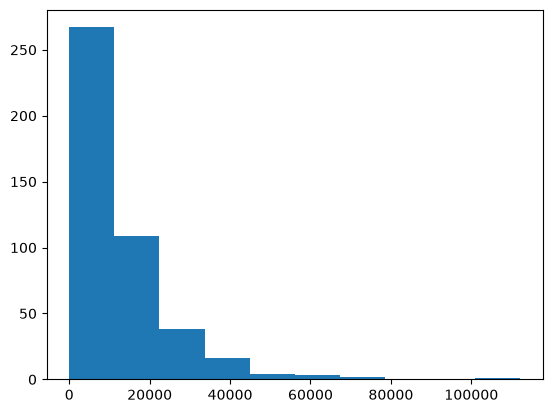

In [11]:
plt.hist(data["Fresh"])
plt.show()

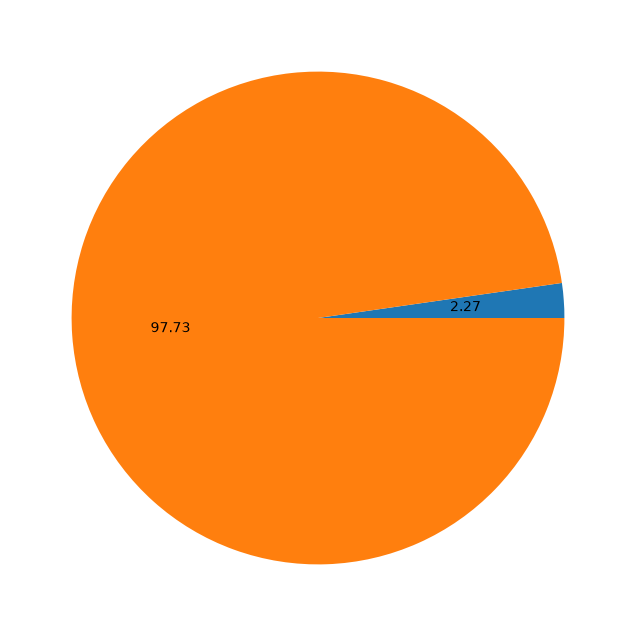

In [12]:
plt.figure(figsize=(8,8))
plt.pie(outliers["Detergents_Paper"],autopct="%.2f")
plt.show()

In [13]:
data_standardized = (data - data.mean())/data.std()
data_standardized.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,1.447005,0.589997,0.052873,0.522972,-0.041068,-0.588697,-0.043519,-0.066264
1,1.447005,0.589997,-0.390857,0.543839,0.170125,-0.269829,0.086309,0.089050
2,1.447005,0.589997,-0.446521,0.408073,-0.028125,-0.137379,0.133080,2.240742
3,-0.689512,0.589997,0.099998,-0.623310,-0.392530,0.686363,-0.498021,0.093305
4,1.447005,0.589997,0.839284,-0.052337,-0.079266,0.173661,-0.231654,1.297870


In [ ]:
Exercise 2.02

In [21]:
data = pd.read_csv("circles.csv")

In [14]:
from sklearn.cluster import KMeans

In [22]:
est_kmeans = KMeans(n_clusters=5, random_state=0)
est_kmeans.fit(data)
pred_kmeans = est_kmeans.predict(data)

In [15]:
ideal_k = []
for i in range(1,21):
    est_kmeans = KMeans(n_clusters=i, random_state=0)
    est_kmeans.fit(data)
    ideal_k.append([i,est_kmeans.inertia_])

In [16]:
ideal_k = np.array(ideal_k)

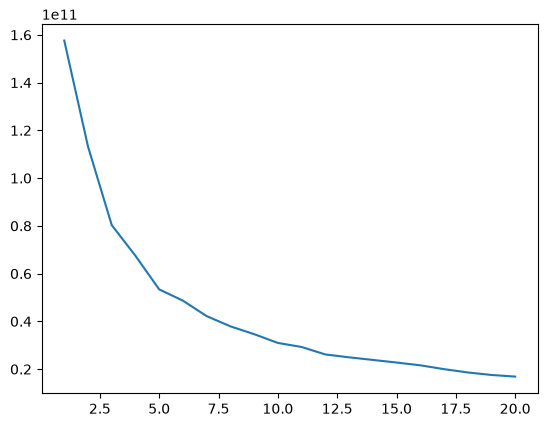

In [17]:
plt.plot(ideal_k[:,0],ideal_k[:,1])
plt.show()

In [18]:
est_kmeans = KMeans(n_clusters=5, random_state=0)
est_kmeans.fit(data)
pred_kmeans = est_kmeans.predict(data)

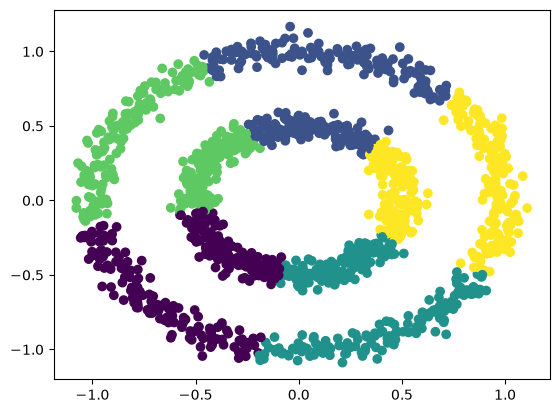

In [23]:
plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=pred_kmeans)
plt.show()